# NLP Final Project — Group 05
## AI-Generated Text Detection: Transformers → Weighted Stacking Ensemble → SHAP + LIME

```
Dataset 1 + Dataset 2
        |
   Preprocessing            (light: whitespace normalization, de-duplication)
        |
 Transformer Models         (8-config hyper-parameter grid each)
   |-- BERT        (bert-base-uncased)
   `-- RoBERTa     (roberta-base)
        |
 Best BERT + Best RoBERTa
        |
 Weighted Stacking Ensemble (LogisticRegression meta-learner on validation probabilities)
        |
      SHAP + LIME
```

No BoW / TF-IDF feature engineering and no classical-ML branch: transformers consume raw text through their own sub-word tokenizers. The Naive Bayes / Logistic Regression / SVM rows of the final table are carried over from the mid-term experiments (see `MIDTERM_RESULTS` in the Table 2 cell).

---
## 0. Environment setup

In [1]:
# NOTE: torch is preinstalled on Colab/Kaggle with the matching CUDA build.
# Do NOT --upgrade it (or numpy) -- that pulls a CPU/mismatched wheel and the next
# `import torch` either hangs on dlopen or fails outright.
import sys
print('python:', sys.version.split()[0])

!pip -q install "transformers>=4.40,<5" "datasets>=2.18" accelerate evaluate shap lime openpyxl

import importlib, torch
print('torch:', torch.__version__, '| cuda available:', torch.cuda.is_available())

python: 3.13.15
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 13.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 36.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.24.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
torch: 2.11.0+cu128 | cuda available: True


> **If pip printed a dependency-conflict warning or asked you to restart:** do it now —
> *Runtime → Restart session* — then run the cell below **without** re-running the install cell.
> Skipping the restart is the usual cause of a hung or interrupted `import torch`.

In [2]:
# Import torch on its own first. It loads large CUDA shared libraries and can take
# 30-90 seconds on a cold runtime -- let it finish, do not press stop.
# (Interrupting it mid-dlopen is what produces `KeyboardInterrupt` inside ctypes.)
import time
_t0 = time.time()
import torch
print(f'torch {torch.__version__} imported in {time.time()-_t0:.1f}s')
print('CUDA available :', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU            :', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU detected. Set Runtime -> Change runtime type -> GPU (T4). '
          'Fine-tuning on CPU is not practical for 32 runs.')

torch 2.11.0+cu128 imported in 0.0s
CUDA available : True
GPU            : Tesla T4


In [ ]:
import os, gc, re, json, time, math, random, shutil, warnings, inspect
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression   # stacking meta-learner
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          AutoConfig, TrainingArguments, Trainer,
                          DataCollatorWithPadding, EarlyStoppingCallback,
                          set_seed as hf_set_seed)

warnings.filterwarnings('ignore')

SEED = 42

def set_all_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    hf_set_seed(seed)

set_all_seeds()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
import transformers
print('Device      :', DEVICE)
print('transformers:', transformers.__version__)
print('torch       :', torch.__version__)

Device      : cuda
transformers: 4.57.6
torch       : 2.11.0+cu128


---
## 1. Configuration

In [5]:
# ---------------- paths ----------------
DATA1_PATH = '/content/AIGTxt(dataset1).xlsx'
DATA2_PATH = '/content/Training_Essay_Data.csv'

WORK_DIR  = 'nlp_final_outputs'
CKPT_DIR  = os.path.join(WORK_DIR, 'checkpoints')
BEST_DIR  = os.path.join(WORK_DIR, 'best_models')
PRED_DIR  = os.path.join(WORK_DIR, 'predictions')
FIG_DIR   = os.path.join(WORK_DIR, 'figures')
for d in (WORK_DIR, CKPT_DIR, BEST_DIR, PRED_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

GRID_RESULTS_CSV = os.path.join(WORK_DIR, 'grid_results.csv')

# ---------------- transformer models ----------------
MODELS = {
    'BERT':    'bert-base-uncased',
    'RoBERTa': 'roberta-base',
}

# ---------------- hyper-parameter grid ----------------
LEARNING_RATES = [2e-5, 3e-5]
BATCH_SIZES    = [16, 32]
WEIGHT_DECAYS  = [0.01, 0.1]
GRID = [{'learning_rate': lr, 'batch_size': bs, 'weight_decay': wd}
        for lr in LEARNING_RATES for bs in BATCH_SIZES for wd in WEIGHT_DECAYS]

# ---------------- fixed hyper-parameters ----------------
EPOCHS          = 5
WARMUP_RATIO    = 0.1
MAX_SEQ_LEN     = 128
DROPOUT         = 0.1
EARLY_STOP_PAT  = 2
EVAL_BATCH_SIZE = 128

# ---------------- ensemble ----------------
STACK_META = 'logreg'         # 'logreg' = weighted stacking meta-learner

# ---------------- speed knobs ----------------
GRID_MAX_TRAIN = {'Dataset 1': None, 'Dataset 2': 8000}
RETRAIN_BEST_ON_FULL = True
FP16 = torch.cuda.is_available()

print(f'{len(GRID)} configs x {len(MODELS)} models x 2 datasets = {len(GRID)*len(MODELS)*2} transformer runs')

8 configs x 2 models x 2 datasets = 32 transformer runs


---
## 2. Data loading

In [6]:
def basic_clean(s):
    s = str(s).replace('\r', ' ')
    s = re.sub(r'\s+', ' ', s)
    return s.strip()


def load_dataset1(path=DATA1_PATH):
    # Sheet 'Form 1' is the wide format: Human-Generated | ChatGPT-Generated | Mixed Text | Domain
    raw = pd.read_excel(path, sheet_name='Form 1')
    human = raw[['Human-Generated']].rename(columns={'Human-Generated': 'text'});   human['label'] = 0
    ai    = raw[['ChatGPT-Generated']].rename(columns={'ChatGPT-Generated': 'text'}); ai['label'] = 1
    df = pd.concat([human, ai], ignore_index=True).dropna(subset=['text'])
    df['text'] = df['text'].apply(basic_clean)
    df = df[df['text'].str.len() > 0].drop_duplicates(subset=['text']).reset_index(drop=True)
    return df[['text', 'label']]


def load_dataset2(path=DATA2_PATH):
    raw = pd.read_csv(path)
    df = raw[['text', 'generated']].rename(columns={'generated': 'label'}).dropna(subset=['text'])
    df['text'] = df['text'].apply(basic_clean)
    df = df[df['text'].str.len() > 0].drop_duplicates(subset=['text']).reset_index(drop=True)
    df['label'] = df['label'].astype(int)
    return df[['text', 'label']]


dataset1 = load_dataset1()
dataset2 = load_dataset2()
DATASETS = {'Dataset 1': dataset1, 'Dataset 2': dataset2}

for name, df in DATASETS.items():
    c = df['label'].value_counts().sort_index()
    wl = df['text'].str.split().str.len()
    print(f'{name}: {len(df):>6} rows | human(0)={c.get(0,0):>6}  ai(1)={c.get(1,0):>6} '
          f'| words mean={wl.mean():.0f} median={wl.median():.0f} p95={wl.quantile(.95):.0f}')
dataset1.head(3)

Dataset 1:   7204 rows | human(0)=  3600  ai(1)=  3604 | words mean=183 median=178 p95=285
Dataset 2:  27282 rows | human(0)= 16098  ai(1)= 11184 | words mean=373 median=345 p95=687


,text,label
0,Photo-realistic image rendering using standard...,0
1,The Large Hadron Collider is exploring physics...,0
2,With the rapid development of mobile Internet ...,0


### 2.1 Train / validation / test split

* **80/20 train-test**, stratified, `random_state=42`.
* A **90/10 train-val** split inside the training portion. Validation drives early stopping, best-config selection, and the stacking meta-learner. **The test set is never used for any decision.**
* The transformer track uses the raw `text` column throughout — no case folding, stop-word removal or lemmatization. Those steps exist to keep a BoW/TF-IDF vocabulary tractable; sub-word tokenizers do not need them, and casing, punctuation and function words are exactly the stylistic cues that separate LLM prose from human prose.

In [7]:
SPLITS = {}
for name, df in DATASETS.items():
    tr_full, te = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df['label'])
    tr, va      = train_test_split(tr_full, test_size=0.1, random_state=SEED, stratify=tr_full['label'])
    SPLITS[name] = {'train': tr.reset_index(drop=True),
                    'val':   va.reset_index(drop=True),
                    'test':  te.reset_index(drop=True)}
    print(f'{name}: train={len(tr):>6} val={len(va):>5} test={len(te):>5} '
          f'(test mix={te["label"].value_counts().sort_index().to_dict()})')

Dataset 1: train=  5186 val=  577 test= 1441 (test mix={0: 720, 1: 721})
Dataset 2: train= 19642 val= 2183 test= 5457 (test mix={0: 3220, 1: 2237})


---
# Stage A — Transformer Models

`bert-base-uncased` and `roberta-base`, each fine-tuned over the 8-config grid on each dataset (32 runs). Both models consume the **raw** `text` column — no BoW/TF-IDF, no classical normalization.

Fixed: epochs = 5 with early stopping (patience 2 on validation F1), warmup ratio = 0.1, max sequence length = 128, dropout = 0.1, optimizer = AdamW.

In [8]:
class TextClsDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=MAX_SEQ_LEN):
        self.enc = tokenizer(list(texts), truncation=True, max_length=max_len, padding=False)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = int(self.labels[i])
        return item


def build_datasets(tokenizer, dataset_name, max_train=None):
    s = SPLITS[dataset_name]
    tr = s['train']
    if max_train is not None and len(tr) > max_train:
        tr, _ = train_test_split(tr, train_size=max_train, random_state=SEED, stratify=tr['label'])
        tr = tr.reset_index(drop=True)
    return (TextClsDataset(tr['text'], tr['label'], tokenizer),
            TextClsDataset(s['val']['text'],  s['val']['label'],  tokenizer),
            TextClsDataset(s['test']['text'], s['test']['label'], tokenizer))


def scores_from_probs(y_true, probs, threshold=0.5):
    preds = (probs[:, 1] >= threshold).astype(int)
    return {'Accuracy':  round(accuracy_score(y_true, preds), 4),
            'Precision': round(precision_score(y_true, preds, zero_division=0), 4),
            'Recall':    round(recall_score(y_true, preds, zero_division=0), 4),
            'F1':        round(f1_score(y_true, preds, zero_division=0), 4)}


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {'accuracy':  accuracy_score(labels, preds),
            'precision': precision_score(labels, preds, zero_division=0),
            'recall':    recall_score(labels, preds, zero_division=0),
            'f1':        f1_score(labels, preds, zero_division=0)}


def softmax_np(x):
    x = x - x.max(axis=-1, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=-1, keepdims=True)


# TrainingArguments renamed `evaluation_strategy` -> `eval_strategy` in transformers 4.46.
_TA_PARAMS = set(inspect.signature(TrainingArguments.__init__).parameters)

def make_training_args(**kw):
    if 'evaluation_strategy' in kw and 'evaluation_strategy' not in _TA_PARAMS:
        kw['eval_strategy'] = kw.pop('evaluation_strategy')
    if 'eval_strategy' in kw and 'eval_strategy' not in _TA_PARAMS:
        kw['evaluation_strategy'] = kw.pop('eval_strategy')
    for k in [k for k in kw if k not in _TA_PARAMS]:
        kw.pop(k)
    return TrainingArguments(**kw)

In [9]:
def run_experiment(model_key, dataset_name, cfg, max_train=None, save_to=None, verbose=True):
    # Fine-tunes one model on one dataset with one config.
    # Returns (result_dict, val_probs, test_probs).
    set_all_seeds(SEED)
    checkpoint = MODELS[model_key]
    tag = (f'{dataset_name.replace(" ", "")}_{model_key}'
           f'_lr{cfg["learning_rate"]:.0e}_bs{cfg["batch_size"]}_wd{cfg["weight_decay"]}')
    out_dir = os.path.join(CKPT_DIR, tag)

    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    train_ds, val_ds, test_ds = build_datasets(tokenizer, dataset_name, max_train=max_train)

    model_cfg = AutoConfig.from_pretrained(checkpoint, num_labels=2)
    model_cfg.hidden_dropout_prob = DROPOUT
    model_cfg.attention_probs_dropout_prob = DROPOUT
    if hasattr(model_cfg, 'classifier_dropout'):
        model_cfg.classifier_dropout = DROPOUT
    model = AutoModelForSequenceClassification.from_pretrained(checkpoint, config=model_cfg)

    args = make_training_args(
        output_dir=out_dir,
        num_train_epochs=EPOCHS,
        learning_rate=cfg['learning_rate'],
        per_device_train_batch_size=cfg['batch_size'],
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        weight_decay=cfg['weight_decay'],
        warmup_ratio=WARMUP_RATIO,
        optim='adamw_torch',
        evaluation_strategy='epoch',
        save_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='f1',
        greater_is_better=True,
        logging_strategy='epoch',
        report_to='none',
        fp16=FP16,
        seed=SEED,
        disable_tqdm=not verbose,
    )

    trainer = Trainer(model=model, args=args,
                      train_dataset=train_ds, eval_dataset=val_ds,
                      tokenizer=tokenizer,
                      data_collator=DataCollatorWithPadding(tokenizer),
                      compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOP_PAT)])

    t0 = time.time()
    trainer.train()
    train_minutes = (time.time() - t0) / 60

    val_probs  = softmax_np(trainer.predict(val_ds).predictions)
    test_probs = softmax_np(trainer.predict(test_ds).predictions)

    y_val  = np.array(SPLITS[dataset_name]['val']['label'])
    y_test = np.array(SPLITS[dataset_name]['test']['label'])
    val_scores  = scores_from_probs(y_val, val_probs)
    test_scores = scores_from_probs(y_test, test_probs)

    if save_to is not None:
        os.makedirs(save_to, exist_ok=True)
        trainer.save_model(save_to)
        tokenizer.save_pretrained(save_to)

    result = {'Dataset': dataset_name, 'Model': model_key,
              'learning_rate': cfg['learning_rate'], 'batch_size': cfg['batch_size'],
              'weight_decay': cfg['weight_decay'],
              'val_F1': val_scores['F1'], 'val_Accuracy': val_scores['Accuracy'],
              'Acc': test_scores['Accuracy'], 'Prec': test_scores['Precision'],
              'Rec': test_scores['Recall'],   'F1': test_scores['F1'],
              'epochs_ran': int(trainer.state.epoch or 0),
              'train_minutes': round(train_minutes, 1), 'n_train': len(train_ds)}

    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)

    return result, val_probs, test_probs

### A.1 Grid search — 32 fine-tuning runs

Every completed run is appended to `grid_results.csv` immediately. If the Colab runtime dies, re-running this cell skips whatever is already recorded and resumes.

In [10]:
def load_grid_results():
    return pd.read_csv(GRID_RESULTS_CSV) if os.path.exists(GRID_RESULTS_CSV) else pd.DataFrame()


def already_done(done_df, dataset_name, model_key, cfg):
    if len(done_df) == 0:
        return False
    m = ((done_df['Dataset'] == dataset_name) & (done_df['Model'] == model_key) &
         np.isclose(done_df['learning_rate'], cfg['learning_rate']) &
         (done_df['batch_size'] == cfg['batch_size']) &
         np.isclose(done_df['weight_decay'], cfg['weight_decay']))
    return bool(m.any())


total, run_i = len(DATASETS) * len(MODELS) * len(GRID), 0

for dataset_name in DATASETS:
    for model_key in MODELS:
        for cfg in GRID:
            run_i += 1
            done_df = load_grid_results()
            if already_done(done_df, dataset_name, model_key, cfg):
                print(f'[{run_i}/{total}] SKIP (cached) {dataset_name} | {model_key} | {cfg}')
                continue
            print(f'\n[{run_i}/{total}] {dataset_name} | {model_key} | '
                  f'lr={cfg["learning_rate"]:.0e} bs={cfg["batch_size"]} wd={cfg["weight_decay"]}')
            res, _, _ = run_experiment(model_key, dataset_name, cfg,
                                       max_train=GRID_MAX_TRAIN.get(dataset_name), verbose=False)
            print('   ->', {k: res[k] for k in ('Acc', 'Prec', 'Rec', 'F1', 'epochs_ran', 'train_minutes')})
            pd.concat([load_grid_results(), pd.DataFrame([res])], ignore_index=True).to_csv(
                GRID_RESULTS_CSV, index=False)

grid_df = load_grid_results()
print(f'\nGrid search complete: {len(grid_df)} runs recorded.')


[1/32] Dataset 1 | BERT | lr=2e-05 bs=16 wd=0.01


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

{'loss': 0.193, 'grad_norm': 0.016198420897126198, 'learning_rate': 2.6746666666666666e-05, 'epoch': 1.0}
{'eval_loss': 0.06936083734035492, 'eval_accuracy': 0.9871736142922584, 'eval_precision': 0.9790055248618784, 'eval_recall': 0.9899441340782122, 'eval_f1': 0.9844444444444445, 'eval_runtime': 3.5353, 'eval_samples_per_second': 617.481, 'eval_steps_per_second': 5.091, 'epoch': 1.0}
{'loss': 0.0444, 'grad_norm': 0.023748213425278664, 'learning_rate': 2.008e-05, 'epoch': 2.0}
{'eval_loss': 0.0403783917427063, 'eval_accuracy': 0.9903802107191938, 'eval_precision': 0.9791666666666666, 'eval_recall': 0.9977653631284916, 'eval_f1': 0.9883785279468733, 'eval_runtime': 3.5712, 'eval_samples_per_second': 611.284, 'eval_steps_per_second': 5.04, 'epoch': 2.0}
{'loss': 0.0097, 'grad_norm': 0.0014199006836861372, 'learning_rate': 1.3413333333333334e-05, 'epoch': 3.0}
{'eval_loss': 0.06253425031900406, 'eval_accuracy': 0.9894640403114979, 'eval_precision': 0.9770240700218819, 'eval_recall': 0.997

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'loss': 0.2158, 'grad_norm': 18.56968879699707, 'learning_rate': 2.68e-05, 'epoch': 1.0}
{'eval_loss': 0.5732253789901733, 'eval_accuracy': 0.901969766376546, 'eval_precision': 0.8087035358114234, 'eval_recall': 0.9966480446927374, 'eval_f1': 0.8928928928928929, 'eval_runtime': 3.6407, 'eval_samples_per_second': 599.611, 'eval_steps_per_second': 4.944, 'epoch': 1.0}
{'loss': 0.0427, 'grad_norm': 0.02067883312702179, 'learning_rate': 2.0133333333333333e-05, 'epoch': 2.0}
{'eval_loss': 0.09218190610408783, 'eval_accuracy': 0.9812185066422354, 'eval_precision': 0.9571734475374732, 'eval_recall': 0.9988826815642458, 'eval_f1': 0.9775833788955713, 'eval_runtime': 3.6845, 'eval_samples_per_second': 592.479, 'eval_steps_per_second': 4.885, 'epoch': 2.0}
{'loss': 0.0093, 'grad_norm': 0.0028250303585082293, 'learning_rate': 1.3466666666666668e-05, 'epoch': 3.0}
{'eval_loss': 0.06688837707042694, 'eval_accuracy': 0.9903802107191938, 'eval_precision': 0.9791666666666666, 'eval_recall': 0.9977653

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'loss': 0.203, 'grad_norm': 0.035308580845594406, 'learning_rate': 2.68e-05, 'epoch': 1.0}
{'eval_loss': 0.051675379276275635, 'eval_accuracy': 0.9903802107191938, 'eval_precision': 0.9921171171171171, 'eval_recall': 0.9843575418994414, 'eval_f1': 0.9882220975883342, 'eval_runtime': 3.64, 'eval_samples_per_second': 599.728, 'eval_steps_per_second': 4.945, 'epoch': 1.0}
{'loss': 0.0361, 'grad_norm': 0.00534948380663991, 'learning_rate': 2.0133333333333333e-05, 'epoch': 2.0}
{'eval_loss': 0.2591016888618469, 'eval_accuracy': 0.9587723316536876, 'eval_precision': 0.9086294416243654, 'eval_recall': 1.0, 'eval_f1': 0.9521276595744681, 'eval_runtime': 3.7303, 'eval_samples_per_second': 585.212, 'eval_steps_per_second': 4.825, 'epoch': 2.0}
{'loss': 0.0088, 'grad_norm': 0.0036683932412415743, 'learning_rate': 1.3466666666666668e-05, 'epoch': 3.0}
{'eval_loss': 0.16299830377101898, 'eval_accuracy': 0.9738891433806688, 'eval_precision': 0.9401260504201681, 'eval_recall': 1.0, 'eval_f1': 0.9691

### A.2 Best config per model, retrained on the full training set

Selection is on **validation** F1, never on test. Because the grid may have run on a sub-sample, the winner is retrained here on the complete training split and its validation/test probabilities are cached — those probabilities are the inputs to the stacking ensemble.

In [11]:
grid_df = load_grid_results()
best_configs = {}

for dataset_name in DATASETS:
    for model_key in MODELS:
        sub = grid_df[(grid_df['Dataset'] == dataset_name) & (grid_df['Model'] == model_key)]
        row = sub.sort_values(['val_F1', 'val_Accuracy'], ascending=False).iloc[0]
        best_configs[(dataset_name, model_key)] = {'learning_rate': float(row['learning_rate']),
                                                   'batch_size': int(row['batch_size']),
                                                   'weight_decay': float(row['weight_decay'])}
        print(f'{dataset_name} | {model_key:<8} -> lr={row["learning_rate"]:.0e} '
              f'bs={int(row["batch_size"])} wd={row["weight_decay"]}  (val F1={row["val_F1"]:.4f})')

with open(os.path.join(WORK_DIR, 'best_configs.json'), 'w') as f:
    json.dump({f'{k[0]}|{k[1]}': v for k, v in best_configs.items()}, f, indent=2)

Dataset 1 | BERT     -> lr=3e-05 bs=16 wd=0.1  (val F1=0.9561)
Dataset 1 | RoBERTa  -> lr=2e-05 bs=32 wd=0.1  (val F1=0.9600)
Dataset 2 | BERT     -> lr=2e-05 bs=16 wd=0.01  (val F1=0.9911)
Dataset 2 | RoBERTa  -> lr=2e-05 bs=16 wd=0.1  (val F1=0.9944)


In [12]:
FINAL_RUNS = {}

for dataset_name in DATASETS:
    for model_key in MODELS:
        cfg = best_configs[(dataset_name, model_key)]
        tag = f'{dataset_name.replace(" ", "")}_{model_key}'
        val_p, test_p = os.path.join(PRED_DIR, f'{tag}_val.npy'), os.path.join(PRED_DIR, f'{tag}_test.npy')

        if os.path.exists(val_p) and os.path.exists(test_p):
            print(f'Loading cached predictions: {dataset_name} | {model_key}')
            val_probs, test_probs = np.load(val_p), np.load(test_p)
            scores = scores_from_probs(np.array(SPLITS[dataset_name]['test']['label']), test_probs)
        else:
            print(f'\nRetraining best {model_key} on full {dataset_name} training set...')
            res, val_probs, test_probs = run_experiment(
                model_key, dataset_name, cfg,
                max_train=None if RETRAIN_BEST_ON_FULL else GRID_MAX_TRAIN.get(dataset_name),
                save_to=os.path.join(BEST_DIR, tag), verbose=True)
            np.save(val_p, val_probs); np.save(test_p, test_probs)
            scores = {'Accuracy': res['Acc'], 'Precision': res['Prec'],
                      'Recall': res['Rec'], 'F1': res['F1']}

        FINAL_RUNS[(dataset_name, model_key)] = {'scores': scores, 'val_probs': val_probs,
                                                 'test_probs': test_probs, 'config': cfg}
        print(f'  {dataset_name} | {model_key}: {scores}')


Retraining best BERT on full Dataset 1 training set...


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.395300,0.382482,0.890815,0.824713,0.993080,0.901099
2,0.164200,0.546676,0.868284,0.793388,0.996540,0.883436
3,0.059400,0.293825,0.941075,0.907348,0.982699,0.943522
4,0.024000,0.260140,0.954939,0.933993,0.979239,0.956081
5,0.007800,0.355863,0.939341,0.901899,0.986159,0.942149


  Dataset 1 | BERT: {'Accuracy': 0.9403, 'Precision': 0.9076, 'Recall': 0.9806, 'F1': 0.9427}

Retraining best RoBERTa on full Dataset 1 training set...


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.129600,0.025528,0.992671,0.997735,0.984358,0.991001
2,0.020000,0.085476,0.984883,0.964440,1.000000,0.981898
3,0.004700,0.080212,0.989464,0.975983,0.998883,0.987300


  Dataset 2 | BERT: {'Accuracy': 0.9914, 'Precision': 0.9973, 'Recall': 0.9817, 'F1': 0.9894}

Retraining best RoBERTa on full Dataset 2 training set...


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.135000,0.020608,0.995877,0.992222,0.997765,0.994986
2,0.018500,0.102903,0.983509,0.961332,1.000000,0.980285
3,0.008200,0.029539,0.994503,0.990011,0.996648,0.993318


  Dataset 2 | RoBERTa: {'Accuracy': 0.9938, 'Precision': 0.9928, 'Recall': 0.992, 'F1': 0.9924}


---
# Stage B — Weighted Stacking Ensemble

A **stacking** ensemble, not a fixed-weight average. The two fine-tuned base models emit `P(AI)` on the held-out validation set; a `LogisticRegression` **meta-learner** is fitted on those two numbers and then applied to the test-set probabilities.

Because the meta-learner is linear, its two coefficients *are* the learned weights — so the ensemble is interpretable and directly comparable to plain weighted voting, which is also computed below as a baseline.

Stacking is done on validation, not training, because base-model probabilities on their own training data are wildly over-confident and would teach the meta-learner the wrong decision boundary. One honest caveat for the report: the same validation set also chose the winning hyper-parameter configs, so it is not perfectly untouched — a third split would be cleaner if you have data to spare.


=== Dataset 1 ===
  stacking coefficients : BERT +3.250 | RoBERTa +4.297 | intercept -4.460
  normalized weight     : BERT 0.43 | RoBERTa 0.57
  STACKING (used)       : {'Accuracy': 0.9514, 'Precision': 0.93, 'Recall': 0.9764, 'F1': 0.9526}
  soft-vote w=0.40 : {'Accuracy': 0.9445, 'Precision': 0.9135, 'Recall': 0.982, 'F1': 0.9465}   <- baseline for comparison


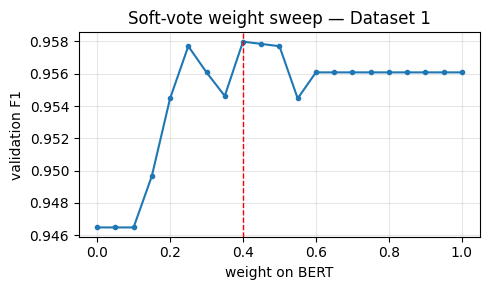


=== Dataset 2 ===
  stacking coefficients : BERT +4.777 | RoBERTa +5.458 | intercept -5.184
  normalized weight     : BERT 0.47 | RoBERTa 0.53
  STACKING (used)       : {'Accuracy': 0.9951, 'Precision': 0.996, 'Recall': 0.992, 'F1': 0.994}
  soft-vote w=0.15 : {'Accuracy': 0.994, 'Precision': 0.9928, 'Recall': 0.9924, 'F1': 0.9926}   <- baseline for comparison


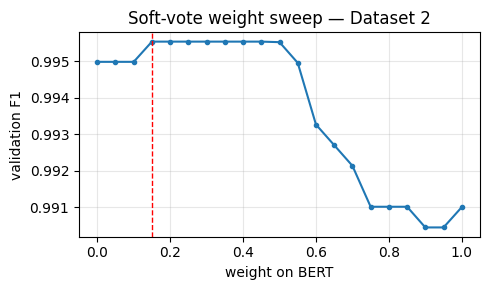

In [13]:
ENSEMBLE = {}

for dataset_name in DATASETS:
    y_val  = np.array(SPLITS[dataset_name]['val']['label'])
    y_test = np.array(SPLITS[dataset_name]['test']['label'])

    v_bert = FINAL_RUNS[(dataset_name, 'BERT')]['val_probs']
    v_rob  = FINAL_RUNS[(dataset_name, 'RoBERTa')]['val_probs']
    t_bert = FINAL_RUNS[(dataset_name, 'BERT')]['test_probs']
    t_rob  = FINAL_RUNS[(dataset_name, 'RoBERTa')]['test_probs']

    # ---- meta-features: P(AI) from each base model ----
    Z_val  = np.column_stack([v_bert[:, 1], v_rob[:, 1]])
    Z_test = np.column_stack([t_bert[:, 1], t_rob[:, 1]])

    meta = LogisticRegression(max_iter=1000)
    meta.fit(Z_val, y_val)
    stack_test_probs = meta.predict_proba(Z_test)
    stack_scores = scores_from_probs(y_test, stack_test_probs)

    w_bert_raw, w_rob_raw = meta.coef_[0]
    denom = abs(w_bert_raw) + abs(w_rob_raw)
    w_bert_norm = w_bert_raw / denom if denom else 0.5

    # ---- baseline: plain weighted soft-voting, weight swept on validation ----
    weights = np.arange(0, 1.001, 0.05)
    val_f1s = [f1_score(y_val, ((w * v_bert + (1 - w) * v_rob)[:, 1] >= .5).astype(int),
                        zero_division=0) for w in weights]
    best_w = float(weights[int(np.argmax(val_f1s))])
    vote_scores = scores_from_probs(y_test, best_w * t_bert + (1 - best_w) * t_rob)

    ENSEMBLE[dataset_name] = {'meta': meta, 'scores': stack_scores,
                              'test_probs': stack_test_probs,
                              'meta_coef': (float(w_bert_raw), float(w_rob_raw)),
                              'meta_intercept': float(meta.intercept_[0]),
                              'w_bert_normalized': float(w_bert_norm),
                              'vote_weight_bert': best_w, 'vote_scores': vote_scores}

    print(f'\n=== {dataset_name} ===')
    print(f'  stacking coefficients : BERT {w_bert_raw:+.3f} | RoBERTa {w_rob_raw:+.3f} '
          f'| intercept {meta.intercept_[0]:+.3f}')
    print(f'  normalized weight     : BERT {w_bert_norm:.2f} | RoBERTa {1-w_bert_norm:.2f}')
    print(f'  STACKING (used)       : {stack_scores}')
    print(f'  soft-vote w={best_w:.2f} : {vote_scores}   <- baseline for comparison')

    plt.figure(figsize=(5, 3))
    plt.plot(weights, val_f1s, marker='o', ms=3)
    plt.axvline(best_w, ls='--', c='r', lw=1)
    plt.xlabel('weight on BERT'); plt.ylabel('validation F1')
    plt.title(f'Soft-vote weight sweep — {dataset_name}')
    plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'ensemble_weight_{dataset_name.replace(" ", "")}.png'), dpi=150)
    plt.show()

---
## Table 1 — Hyper-parameter grid results

The layout of the first required table. The ENSEMBLE row is appended at the bottom, as in the assignment sheet.

In [14]:
grid_df = load_grid_results()

table1 = grid_df.pivot_table(index=['Model', 'learning_rate', 'batch_size', 'weight_decay'],
                             columns='Dataset', values=['Acc', 'Prec', 'Rec', 'F1'])
table1 = table1.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0)
order  = [(ds, m) for ds in ['Dataset 1', 'Dataset 2'] for m in ['Acc', 'Prec', 'Rec', 'F1']]
table1 = table1[[c for c in order if c in table1.columns]]
table1 = table1.reindex(['BERT', 'RoBERTa'], level=0)

ens_row = {}
for ds in DATASETS:
    s = ENSEMBLE[ds]['scores']
    ens_row[(ds, 'Acc')]  = s['Accuracy']; ens_row[(ds, 'Prec')] = s['Precision']
    ens_row[(ds, 'Rec')]  = s['Recall'];   ens_row[(ds, 'F1')]   = s['F1']
ens_df = pd.DataFrame([ens_row],
                      index=pd.MultiIndex.from_tuples([('ENSEMBLE', '', '', '')],
                                                      names=table1.index.names))
table1_full = pd.concat([table1, ens_df[[c for c in table1.columns]]])

table1_full.to_csv(os.path.join(WORK_DIR, 'table1_grid_search.csv'))
table1_full.round(4)

Dataset 1                  \
                                                     Acc    Prec     Rec   
Model    learning_rate batch_size weight_decay                             
BERT     0.00002       16         0.01            0.9368  0.9049  0.9764   
                                  0.1             0.9285  0.9034  0.9598   
                       32         0.01            0.8945  0.8399  0.9750   
                                  0.1             0.9202  0.8750  0.9806   
         0.00003       16         0.01            0.9278  0.8890  0.9778   
                                  0.1             0.9403  0.9076  0.9806   
                       32         0.01            0.9209  0.8847  0.9681   
                                  0.1             0.9341  0.8992  0.9778   
RoBERTa  0.00002       16         0.01            0.9313  0.9158  0.9501   
                                  0.1             0.9313  0.9191  0.9459   
                       32         0.01            0.9188  0.8692  0.9861   
                                  0.1             0.9424  0.9100  0.9820   
         0.00003       16         0.01            0.9396  0.9054  0.9820   
                                  0.1             0.9417  0.9027  0.9903   
                       32         0.01            0.9105  0.8566  0.9861   
                                  0.1             0.9001  0.8382  0.9917   
ENSEMBLE                                          0.9514  0.9300  0.9764   

                                                       Dataset 2          \
                                                    F1       Acc    Prec   
Model    learning_rate batch_size weight_decay                             
BERT     0.00002       16         0.01          0.9393    0.9903  0.9858   
                                  0.1           0.9307    0.9848  0.9753   
                       32         0.01          0.9024    0.9782  0.9537   
                                  0.1           0.9248    0.9859  0.9712   
         0.00003       16         0.01          0.9313    0.9864  0.9813   
                                  0.1           0.9427    0.9890  0.9888   
                       32         0.01          0.9245    0.9890  0.9793   
                                  0.1           0.9369    0.9883  0.9827   
RoBERTa  0.00002       16         0.01          0.9326    0.9927  0.9911   
                                  0.1           0.9323    0.9941  0.9937   
                       32         0.01          0.9240    0.9828  0.9649   
                                  0.1           0.9446    0.9831  0.9649   
         0.00003       16         0.01          0.9421    0.9885  0.9780   
                                  0.1           0.9444    0.9905  0.9845   
                       32         0.01          0.9168    0.9879  0.9776   
                                  0.1           0.9085    0.9912  0.9928   
ENSEMBLE                                        0.9526    0.9951  0.9960   

                                                                
                                                   Rec      F1  
Model    learning_rate batch_size weight_decay                  
BERT     0.00002       16         0.01          0.9906  0.9882  
                                  0.1           0.9879  0.9816  
                       32         0.01          0.9951  0.9740  
                                  0.1           0.9951  0.9830  
         0.00003       16         0.01          0.9857  0.9835  
                                  0.1           0.9844  0.9866  
                       32         0.01          0.9942  0.9867  
                                  0.1           0.9888  0.9857  
RoBERTa  0.00002       16         0.01          0.9911  0.9911  
                                  0.1           0.9920  0.9928  
                       32         0.01          0.9942  0.9793  
                                  0.1           0.9951  0.9798  
         0.00003       16     

---
## Table 2 — Final model comparison

All six rows from one run on one identical test split.

In [15]:
ROW_ORDER = ['Naive Bayes', 'Logistic Regression', 'Support Vector Machine',
             'BERT', 'Your BERT Variation (RoBERTa)', 'ENSEMBLE']

# Naive Bayes / Logistic Regression / SVM come from the MID-TERM experiments.
# Best representation per model by accuracy: NB -> BoW (both datasets),
# LR -> TF-IDF on D1 / BoW on D2, SVM -> TF-IDF (both). Edit if your report picks differently.
MIDTERM_RESULTS = {
    'Naive Bayes':            {'Dataset 1': {'Accuracy': .8419, 'Precision': .8674, 'Recall': .8072, 'F1': .8362},
                               'Dataset 2': {'Accuracy': .9715, 'Precision': .9771, 'Recall': .9527, 'F1': .9648}},
    'Logistic Regression':    {'Dataset 1': {'Accuracy': .8904, 'Precision': .9220, 'Recall': .8530, 'F1': .8862},
                               'Dataset 2': {'Accuracy': .9931, 'Precision': .9889, 'Recall': .9942, 'F1': .9916}},
    'Support Vector Machine': {'Dataset 1': {'Accuracy': .8946, 'Precision': .9141, 'Recall': .8710, 'F1': .8920},
                               'Dataset 2': {'Accuracy': .9936, 'Precision': .9924, 'Recall': .9920, 'F1': .9922}},
}

def classical_scores(model_name, ds):
    return MIDTERM_RESULTS[model_name][ds]

METRIC_KEYS = [('Acc', 'Accuracy'), ('Prec', 'Precision'), ('Rec', 'Recall'), ('F1', 'F1')]

rows = []
def add_row(display_name, getter):
    r = {'Model': display_name}
    for ds in DATASETS:
        s = getter(ds)
        for short, long in METRIC_KEYS:
            r[(ds, short)] = s[long]
    rows.append(r)

for m in ['Naive Bayes', 'Logistic Regression', 'Support Vector Machine']:
    add_row(m, lambda ds, m=m: classical_scores(m, ds))
add_row('BERT', lambda ds: FINAL_RUNS[(ds, 'BERT')]['scores'])
add_row('Your BERT Variation (RoBERTa)', lambda ds: FINAL_RUNS[(ds, 'RoBERTa')]['scores'])
add_row('ENSEMBLE', lambda ds: ENSEMBLE[ds]['scores'])

final_table = pd.DataFrame(rows).set_index('Model')
final_table.columns = pd.MultiIndex.from_tuples(final_table.columns)
final_table = final_table[[(ds, m) for ds in ['Dataset 1', 'Dataset 2']
                           for m, _ in METRIC_KEYS]]
final_table = final_table.reindex(ROW_ORDER)
final_table.to_csv(os.path.join(WORK_DIR, 'table2_final_comparison.csv'))

print('Rows 1-3 come from the mid-term experiments; rows 4-6 from this notebook.')
print('\nFINAL COMPARISON TABLE')
final_table.round(4)

Rows 1-3 come from the mid-term experiments; rows 4-6 from this notebook.

FINAL COMPARISON TABLE


Dataset 1                         Dataset 2  \
                                    Acc    Prec     Rec      F1       Acc   
Model                                                                       
Naive Bayes                      0.8419  0.8674  0.8072  0.8362    0.9715   
Logistic Regression              0.8904  0.9220  0.8530  0.8862    0.9931   
Support Vector Machine           0.8946  0.9141  0.8710  0.8920    0.9936   
BERT                             0.9403  0.9076  0.9806  0.9427    0.9914   
Your BERT Variation (RoBERTa)    0.9382  0.9104  0.9723  0.9403    0.9938   
ENSEMBLE                         0.9514  0.9300  0.9764  0.9526    0.9951   

                                                       
                                 Prec     Rec      F1  
Model                                                  
Naive Bayes                    0.9771  0.9527  0.9648  
Logistic Regression            0.9889  0.9942  0.9916  
Support Vector Machine         0.9924  0.9920  0.9922  
BERT                           0.9973  0.9817  0.9894  
Your BERT Variation (RoBERTa)  0.9928  0.9920  0.9924  
ENSEMBLE                       0.9960  0.9920  0.9940

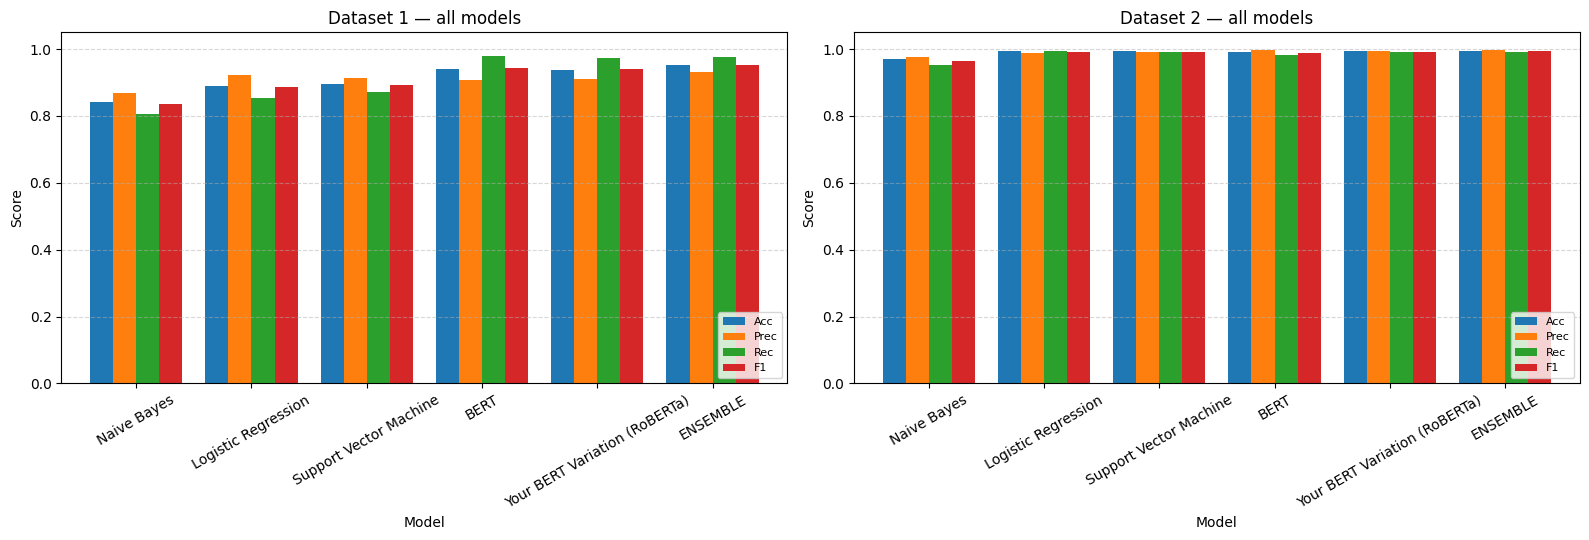

In [16]:
metrics_short = ['Acc', 'Prec', 'Rec', 'F1']

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, ds in zip(axes, ['Dataset 1', 'Dataset 2']):
    final_table[ds][metrics_short].plot(kind='bar', ax=ax, width=0.8)
    ax.set_title(f'{ds} — all models'); ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', rotation=30); ax.grid(axis='y', ls='--', alpha=.5)
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'final_comparison.png'), dpi=150)
plt.show()

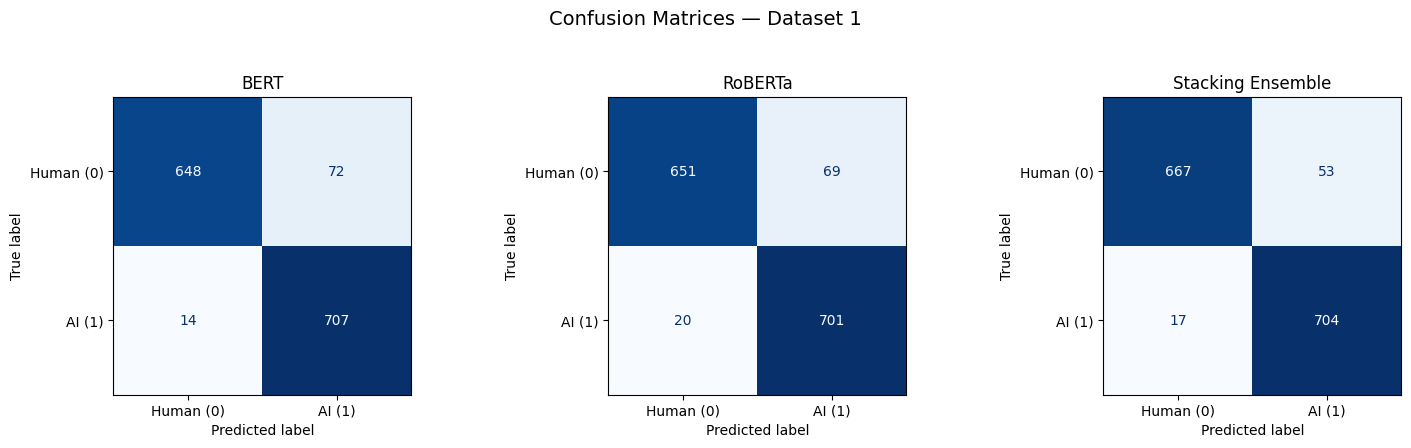


=== Dataset 1 | Stacking ensemble classification report ===
              precision    recall  f1-score   support

   Human (0)     0.9751    0.9264    0.9501       720
      AI (1)     0.9300    0.9764    0.9526       721

    accuracy                         0.9514      1441
   macro avg     0.9526    0.9514    0.9514      1441
weighted avg     0.9526    0.9514    0.9514      1441



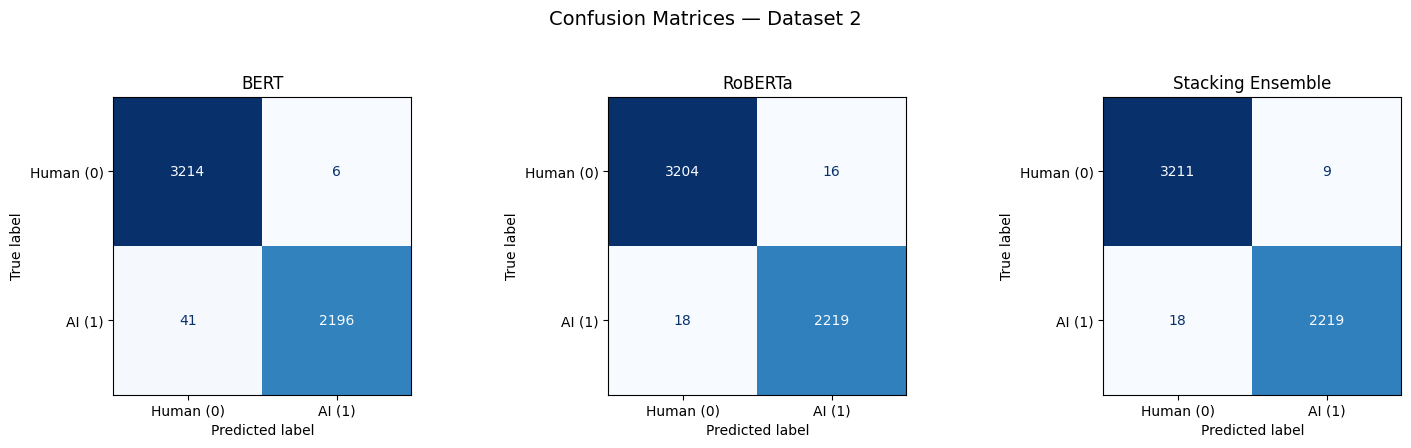


=== Dataset 2 | Stacking ensemble classification report ===
              precision    recall  f1-score   support

   Human (0)     0.9944    0.9972    0.9958      3220
      AI (1)     0.9960    0.9920    0.9940      2237

    accuracy                         0.9951      5457
   macro avg     0.9952    0.9946    0.9949      5457
weighted avg     0.9951    0.9951    0.9951      5457



In [17]:
for ds in DATASETS:
    y_test = np.array(SPLITS[ds]['test']['label'])
    panels = [('BERT', FINAL_RUNS[(ds, 'BERT')]['test_probs']),
              ('RoBERTa', FINAL_RUNS[(ds, 'RoBERTa')]['test_probs']),
              ('Stacking Ensemble', ENSEMBLE[ds]['test_probs'])]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    fig.suptitle(f'Confusion Matrices — {ds}', fontsize=14)
    for ax, (nm, probs) in zip(axes, panels):
        cm = confusion_matrix(y_test, (probs[:, 1] >= .5).astype(int))
        ConfusionMatrixDisplay(cm, display_labels=['Human (0)', 'AI (1)']).plot(
            ax=ax, colorbar=False, cmap='Blues')
        ax.set_title(nm)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig(os.path.join(FIG_DIR, f'cm_{ds.replace(" ", "")}.png'), dpi=150)
    plt.show()

    print(f'\n=== {ds} | Stacking ensemble classification report ===')
    print(classification_report(y_test, (ENSEMBLE[ds]['test_probs'][:, 1] >= .5).astype(int),
                                target_names=['Human (0)', 'AI (1)'], digits=4))

---
# Stage C — Explainability: SHAP + LIME

Both explainers need one black-box function `texts -> probabilities`. The wrapper below runs raw strings through **both** fine-tuned base models and pushes their `P(AI)` through the fitted stacking meta-learner — so what gets explained is the deployed ensemble, not one of its halves.

In [18]:
EXPLAIN_DATASET = 'Dataset 1'      # switch to 'Dataset 2' to explain the essay model

_loaded = {}
def get_model(dataset_name, model_key):
    key = (dataset_name, model_key)
    if key not in _loaded:
        path = os.path.join(BEST_DIR, f'{dataset_name.replace(" ", "")}_{model_key}')
        tok = AutoTokenizer.from_pretrained(path)
        mdl = AutoModelForSequenceClassification.from_pretrained(path).to(DEVICE).eval()
        _loaded[key] = (tok, mdl)
    return _loaded[key]


def base_probs(texts, dataset_name, model_key, batch_size=64):
    tok, mdl = get_model(dataset_name, model_key)
    out = []
    for i in range(0, len(texts), batch_size):
        batch = tok(texts[i:i + batch_size], truncation=True, max_length=MAX_SEQ_LEN,
                    padding=True, return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            out.append(softmax_np(mdl(**batch).logits.detach().cpu().numpy()))
    return np.vstack(out)


def ensemble_predict_proba(texts, dataset_name=None, batch_size=64):
    ds = dataset_name or EXPLAIN_DATASET
    texts = [str(t) for t in (texts.tolist() if isinstance(texts, np.ndarray) else texts)]
    p_bert = base_probs(texts, ds, 'BERT', batch_size)
    p_rob  = base_probs(texts, ds, 'RoBERTa', batch_size)
    Z = np.column_stack([p_bert[:, 1], p_rob[:, 1]])
    return ENSEMBLE[ds]['meta'].predict_proba(Z).astype(np.float64)


_demo = SPLITS[EXPLAIN_DATASET]['test']['text'].iloc[:3].tolist()
print(ensemble_predict_proba(_demo).round(4))

[[0.9777 0.0223]
 [0.7894 0.2106]
 [0.988  0.012 ]]


### C.1 SHAP

A regex word-masker is used rather than a model tokenizer: the ensemble contains two different tokenizers (WordPiece vs BPE), so attributing to plain words keeps one explanation valid for both halves and readable in the report.

SHAP is expensive here — each explanation is hundreds of masked forward passes through two transformers. Start small.

In [19]:
import shap

N_SHAP_PER_CLASS = 2
MAX_CHARS = 600     # the model only sees 128 tokens anyway

test_df = SPLITS[EXPLAIN_DATASET]['test']
shap_samples = (test_df.groupby('label', group_keys=False)
                       .apply(lambda g: g.sample(min(N_SHAP_PER_CLASS, len(g)), random_state=SEED)))
shap_texts  = [t[:MAX_CHARS] for t in shap_samples['text'].tolist()]
shap_labels = shap_samples['label'].tolist()

masker    = shap.maskers.Text(r'\W+')
explainer = shap.Explainer(lambda x: ensemble_predict_proba(x), masker,
                           output_names=['Human', 'AI'])
shap_values = explainer(shap_texts)
print('SHAP values computed for', len(shap_texts), 'samples.')

PartitionExplainer explainer:  50%|█████     | 2/4 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 5it [00:22,  7.67s/it]

SHAP values computed for 4 samples.


In [20]:
for i, (txt, lab) in enumerate(zip(shap_texts, shap_labels)):
    p = ensemble_predict_proba([txt])[0]
    print(f'\n--- Sample {i} | true={"AI" if lab == 1 else "Human"} | '
          f'P(AI)={p[1]:.4f} -> predicted {"AI" if p[1] >= .5 else "Human"} ---')
    shap.plots.text(shap_values[i, :, 'AI'])


--- Sample 0 | true=Human | P(AI)=0.0121 -> predicted Human ---



--- Sample 1 | true=Human | P(AI)=0.0206 -> predicted Human ---



--- Sample 2 | true=AI | P(AI)=0.8797 -> predicted AI ---



--- Sample 3 | true=AI | P(AI)=0.9554 -> predicted AI ---


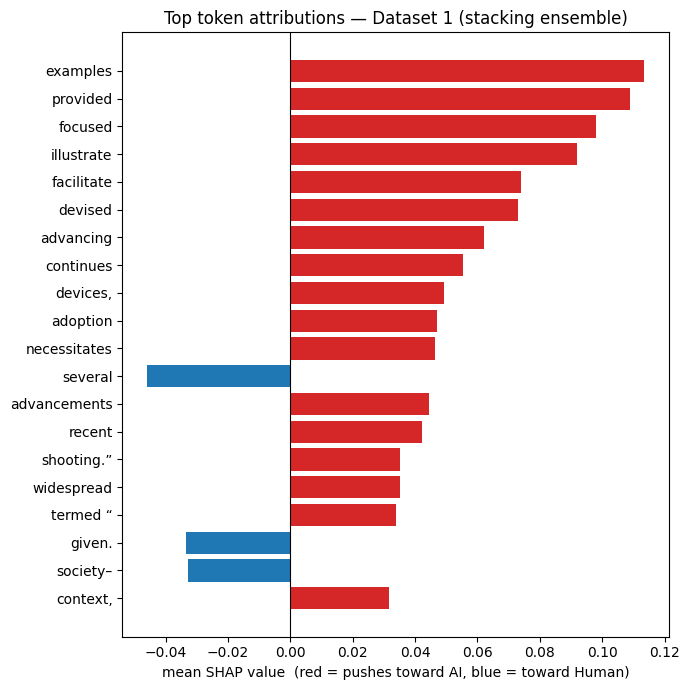

,word,mean_shap,mean_abs_shap,n
125,examples,0.113402,0.113402,1
126,provided,0.108876,0.108876,1
178,focused,0.098142,0.098142,1
127,illustrate,0.092041,0.092041,1
202,facilitate,0.073937,0.073937,1
201,devised,0.073082,0.073082,1
192,advancing,0.061994,0.061994,1
225,continues,0.055303,0.055303,1
208,"devices,",0.049237,0.049237,1
221,adoption,0.047169,0.047169,1


In [21]:
# Aggregate token attributions across the sampled texts.
# (shap.plots.bar cannot average text Explanations directly -- each row has a different
#  token list -- so the pooling is done by word here.)
acc = defaultdict(list)
for i in range(len(shap_texts)):
    vals = shap_values[i].values[:, 1]          # attribution toward the AI class
    for tok, v in zip(shap_values[i].data, vals):
        w = tok.strip().lower()
        if w:
            acc[w].append(v)

agg = (pd.DataFrame([{'word': w, 'mean_shap': np.mean(v),
                      'mean_abs_shap': np.mean(np.abs(v)), 'n': len(v)}
                     for w, v in acc.items()])
         .sort_values('mean_abs_shap', ascending=False))
agg.to_csv(os.path.join(WORK_DIR, 'shap_word_importance.csv'), index=False)

top = agg.head(20).iloc[::-1]
plt.figure(figsize=(7, 7))
plt.barh(top['word'], top['mean_shap'],
         color=['#d62728' if v > 0 else '#1f77b4' for v in top['mean_shap']])
plt.axvline(0, c='k', lw=.8)
plt.xlabel('mean SHAP value  (red = pushes toward AI, blue = toward Human)')
plt.title(f'Top token attributions — {EXPLAIN_DATASET} (stacking ensemble)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'shap_bar.png'), dpi=150, bbox_inches='tight')
plt.show()
agg.head(20)

### C.2 LIME

LIME fits a sparse local linear surrogate by perturbing words — cheaper than SHAP, so more samples are practical. `num_samples=800` is a reasonable accuracy/time trade-off; raise it if explanations look unstable across reruns.


=== LIME sample 0 | true=Human | P(AI)=0.0121 ===
   This                      +0.0000  -> AI
   nodes                     -0.0000  -> Human
   paradigm                  +0.0000  -> AI
   its                       -0.0000  -> Human
   leads                     +0.0000  -> AI
   the                       +0.0000  -> AI
   modifications             +0.0000  -> AI
   many                      -0.0000  -> Human
   using                     -0.0000  -> Human
   of                        -0.0000  -> Human
   important                 -0.0000  -> Human
   specific                  +0.0000  -> AI
   communicating             +0.0000  -> AI
   electronic                -0.0000  -> Human
   previous                  -0.0000  -> Human


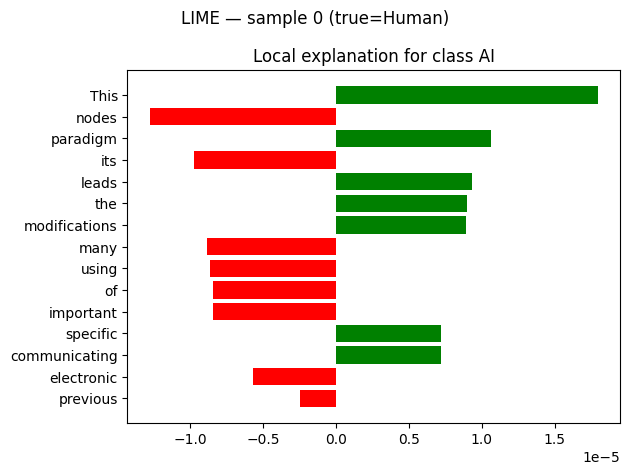


=== LIME sample 1 | true=Human | P(AI)=0.0206 ===
   necessitates              +0.0011  -> AI
   the                       +0.0010  -> AI
   examination               +0.0007  -> AI
   while                     +0.0007  -> AI
   of                        +0.0007  -> AI
   Increased                 +0.0007  -> AI
   context                   +0.0007  -> AI
   this                      +0.0006  -> AI
   rests                     +0.0006  -> AI
   integral                  +0.0006  -> AI
   dependency                +0.0006  -> AI
   on                        +0.0006  -> AI
   new                       -0.0004  -> Human
   other                     -0.0004  -> Human
   fact                      -0.0002  -> Human


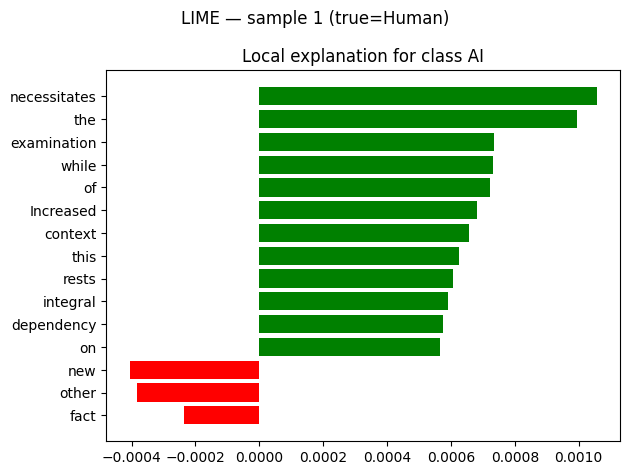


=== LIME sample 2 | true=AI | P(AI)=0.8797 ===
   this                      +0.0849  -> AI
   in                        +0.0799  -> AI
   illustrate                +0.0788  -> AI
   context                   +0.0768  -> AI
   The                       +0.0765  -> AI
   termed                    +0.0751  -> AI
   approximates              +0.0726  -> AI
   a                         +0.0661  -> AI
   independent               +0.0593  -> AI
   provided                  +0.0592  -> AI
   represent                 +0.0586  -> AI
   that                      +0.0583  -> AI
   they                      +0.0545  -> AI
   random                    -0.0106  -> Human
   1500                      -0.0065  -> Human


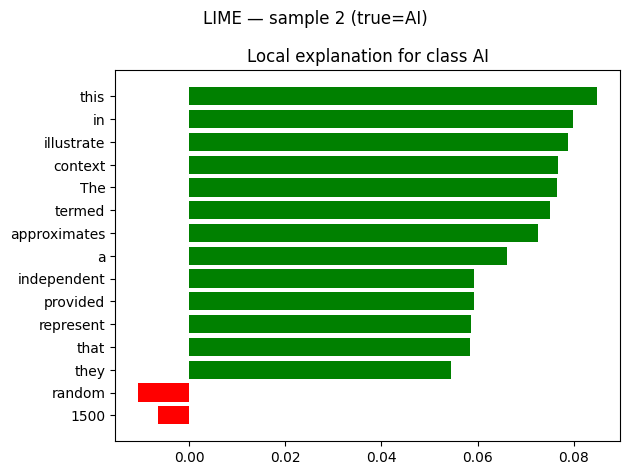


=== LIME sample 3 | true=AI | P(AI)=0.9554 ===
   focused                   +0.2061  -> AI
   eliminating               +0.1717  -> AI
   Nevertheless              +0.1419  -> AI
   Furthermore               +0.1371  -> AI
   impeded                   +0.1164  -> AI
   advancements              +0.1084  -> AI
   Recent                    +0.0995  -> AI
   to                        +0.0956  -> AI
   continues                 +0.0921  -> AI
   advancing                 +0.0854  -> AI
   discovery                 +0.0848  -> AI
   the                       +0.0755  -> AI
   networking                +0.0719  -> AI
   facilitate                +0.0717  -> AI
   established               -0.0343  -> Human


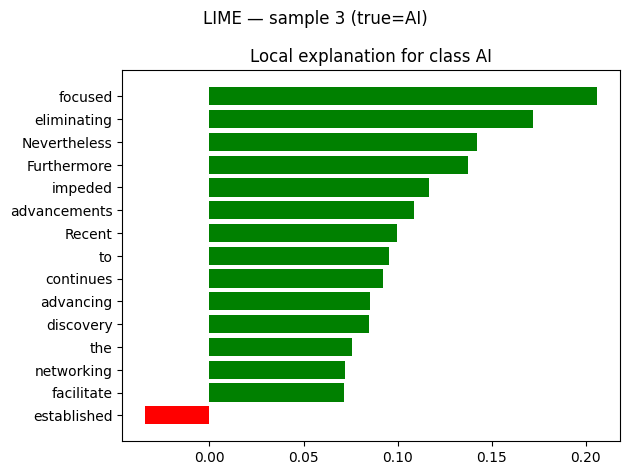

,sample,true_label,p_ai,html
0,0,0,0.012075,nlp_final_outputs/lime_sample0.html
1,1,0,0.020562,nlp_final_outputs/lime_sample1.html
2,2,1,0.879664,nlp_final_outputs/lime_sample2.html
3,3,1,0.955441,nlp_final_outputs/lime_sample3.html


In [22]:
from lime.lime_text import LimeTextExplainer

lime_explainer = LimeTextExplainer(class_names=['Human', 'AI'], random_state=SEED)
N_LIME_PER_CLASS = 2

lime_samples = (test_df.groupby('label', group_keys=False)
                       .apply(lambda g: g.sample(min(N_LIME_PER_CLASS, len(g)), random_state=SEED)))

lime_records = []
for idx, (txt, lab) in enumerate(zip(lime_samples['text'], lime_samples['label'])):
    txt = txt[:MAX_CHARS]
    exp = lime_explainer.explain_instance(txt, ensemble_predict_proba,
                                          num_features=15, num_samples=800, labels=(1,))
    p = ensemble_predict_proba([txt])[0]

    print(f'\n=== LIME sample {idx} | true={"AI" if lab == 1 else "Human"} | P(AI)={p[1]:.4f} ===')
    for word, weight in exp.as_list(label=1):
        print(f'   {word:<25} {weight:+.4f}  -> {"AI" if weight > 0 else "Human"}')

    fig = exp.as_pyplot_figure(label=1)
    fig.suptitle(f'LIME — sample {idx} (true={"AI" if lab == 1 else "Human"})')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'lime_sample{idx}.png'), dpi=150, bbox_inches='tight')
    plt.show()

    html_path = os.path.join(WORK_DIR, f'lime_sample{idx}.html')
    exp.save_to_file(html_path)
    lime_records.append({'sample': idx, 'true_label': int(lab), 'p_ai': float(p[1]),
                         'top_features': exp.as_list(label=1), 'html': html_path})

pd.DataFrame(lime_records)[['sample', 'true_label', 'p_ai', 'html']]

### C.3 SHAP vs LIME agreement

Take the top-k words each method flags for the same instance and measure the overlap. High agreement is evidence the explanation reflects the model rather than the explainer — a much stronger claim for the report than "both highlight similar words".

In [23]:
def top_words_shap(sv_row, k=10):
    vals = sv_row.values[:, 1] if sv_row.values.ndim > 1 else sv_row.values
    toks = [t.strip() for t in sv_row.data]
    order = np.argsort(-np.abs(vals))[:k]
    return [toks[i] for i in order if toks[i]]


def top_words_lime(text, k=10):
    exp = lime_explainer.explain_instance(text, ensemble_predict_proba,
                                          num_features=k, num_samples=800, labels=(1,))
    return [w for w, _ in exp.as_list(label=1)]


K, agreement = 10, []
for i, txt in enumerate(shap_texts):
    s = set(w.lower() for w in top_words_shap(shap_values[i], K))
    l = set(w.lower() for w in top_words_lime(txt, K))
    inter = s & l
    agreement.append({'sample': i, 'shap_top': len(s), 'lime_top': len(l),
                      'overlap': len(inter),
                      'jaccard': round(len(inter) / max(len(s | l), 1), 3),
                      'shared_words': ', '.join(sorted(inter))})

agree_df = pd.DataFrame(agreement)
agree_df.to_csv(os.path.join(WORK_DIR, 'shap_lime_agreement.csv'), index=False)
agree_df

,sample,shap_top,lime_top,overlap,jaccard,shared_words
0,0,9,9,1,0.059,ultrasmall
1,1,10,10,3,0.176,"dependency, necessitates, technologies"
2,2,9,10,1,0.056,examples
3,3,10,10,4,0.250,"advancements, advancing, facilitate, focused"


---
## Save everything

In [24]:
with pd.ExcelWriter(os.path.join(WORK_DIR, 'all_results.xlsx')) as xl:
    load_grid_results().to_excel(xl, sheet_name='grid_search_raw', index=False)
    table1_full.round(4).to_excel(xl, sheet_name='table1_grid')
    final_table.round(4).to_excel(xl, sheet_name='table2_final')
    pd.DataFrame([{'Dataset': ds,
                   'meta_coef_BERT': ENSEMBLE[ds]['meta_coef'][0],
                   'meta_coef_RoBERTa': ENSEMBLE[ds]['meta_coef'][1],
                   'meta_intercept': ENSEMBLE[ds]['meta_intercept'],
                   'normalized_w_BERT': round(ENSEMBLE[ds]['w_bert_normalized'], 3),
                   'softvote_w_BERT': ENSEMBLE[ds]['vote_weight_bert'],
                   **ENSEMBLE[ds]['scores']} for ds in DATASETS]
                ).to_excel(xl, sheet_name='ensemble', index=False)

shutil.make_archive('nlp_final_results', 'zip', WORK_DIR)
print('Wrote nlp_final_results.zip')

try:
    from google.colab import files
    files.download('nlp_final_results.zip')
except Exception as e:
    print('(not on Colab - download manually)', e)

Wrote nlp_final_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Notes for the report

1. **Why the mid-term preprocessing is gone.** BoW/TF-IDF need aggressive normalization to keep the vocabulary tractable; sub-word tokenizers do not. Stop-words, casing and punctuation are exactly the stylistic cues that separate LLM prose from human prose, and the mid-term WordNet synonym substitution actively corrupted meaning (`rendering → rendition`, `tracking → trailing`). Feeding raw text is the correct choice here, not a shortcut — say so in the methodology section rather than leaving it unexplained.

2. **Comparability caveat.** The transformer test split uses the same seed and ratio as the mid-term, but whitespace collapsing changes which rows survive de-duplication, so the two test sets are not byte-identical (Dataset 1: 7,204 rows here vs 7,208 in the mid-term; Dataset 2: 27,282 vs 27,340). One line in the limitations paragraph covers it.

3. **`max_length = 128`.** Dataset 2 essays average ~380 words, so the model reads roughly the first third. That the models still score high suggests the AI/human signal is front-loaded and stylistic. A 256-token ablation on one config is a strong optional addition.

4. **Ceiling effect on Dataset 2.** The classical SVM already reaches ~99%. Do not expect a dramatic transformer gain there — the interesting comparison is Dataset 1, where the classical ceiling was ~89%.

5. **Report the stacking coefficients.** They show which base model the ensemble actually trusts. If one coefficient is near zero, the ensemble has collapsed into a single model — say so rather than presenting it as a genuine combination. The soft-vote baseline printed alongside makes that easy to check.

6. **Meta-learner caveat.** The stacking layer is fitted on the same validation set that selected the hyper-parameter configs. A dedicated third split would be cleaner; with these dataset sizes it is a reasonable trade-off, but it belongs in the limitations paragraph.